# 02 — Modelagem: calibração, estabilidade do score e trade-off do limiar

Leitura do **champion registrado** (alias `champion` no MLflow). Os modelos e as métricas vêm do run
`RUN-20261112-train-REF-02`; aqui só se visualiza o que o treino produziu. Somente agregados.
Toda lógica vem de `src/` (partição interna, métricas, limiar) — nada é reimplementado.

In [1]:
import os, sys, json, warnings
from pathlib import Path

warnings.filterwarnings("ignore", message="IProgress not found")

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT)); os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from mlflow import MlflowClient

from src.models.dataset import internal_split, load_partition, oot_sets, xy
from src.models.metrics import calibration_table, decision_metrics
from src.models.registry import CHAMPION, load_alias, setup_tracking
from src.models.settings import load_cost_config, load_training_config
from src.models.threshold import expected_value, loan_economics, threshold_grid

cfg, cost = load_training_config(), load_cost_config()
setup_tracking("training")
mv = MlflowClient().get_model_version_by_alias(cfg.registry_model_name, CHAMPION)
model = load_alias(cfg.registry_model_name)
profile = json.loads((ROOT / "models" / "reference_profile.json").read_text(encoding="utf-8"))
sets = internal_split(load_partition("reference"), cfg)
sets |= oot_sets(load_partition("production"), cfg)
scores = {k: model.predict_proba(xy(sets[k])[0])[:, 1] for k in ("calibration", "test", "oot_2014", "oot_2015")}
print(f"champion: {cfg.registry_model_name} v{mv.version} (run {mv.run_id}) · limiar {profile['threshold']}")

champion: credit-scoring v1 (run 500f5b3fcc4345d59019dfd1097689a0) · limiar 0.33


## 1. Curva de calibração (decis do score)

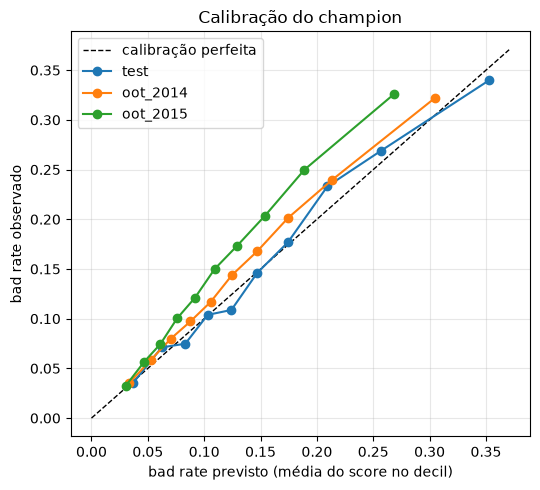

In [2]:
tables = {k: calibration_table(xy(sets[k])[1].to_numpy(), scores[k]) for k in ("test", "oot_2014", "oot_2015")}
fig, ax = plt.subplots(figsize=(5.5, 5))
lim = max(t[["predicted", "observed"]].to_numpy().max() for t in tables.values()) * 1.05
ax.plot([0, lim], [0, lim], "k--", lw=1, label="calibração perfeita")
for name, t in tables.items():
    ax.plot(t["predicted"], t["observed"], marker="o", label=name)
ax.set_xlabel("bad rate previsto (média do score no decil)"); ax.set_ylabel("bad rate observado")
ax.set_title("Calibração do champion"); ax.legend(); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

In [3]:
pd.concat({k: t.round(4) for k, t in tables.items()}, axis=1)

test                    oot_2014                    oot_2015            \
      n predicted observed        n predicted observed        n predicted   
0  1618    0.0368   0.0352    17551    0.0336   0.0355    28279    0.0304   
1  1618    0.0623   0.0711    17551    0.0530   0.0589    28279    0.0469   
2  1617    0.0832   0.0748    17551    0.0703   0.0798    28278    0.0611   
3  1618    0.1031   0.1038    17551    0.0878   0.0973    28279    0.0760   
4  1618    0.1241   0.1088    17551    0.1056   0.1167    28279    0.0918   
5  1617    0.1470   0.1459    17550    0.1248   0.1440    28278    0.1093   
6  1618    0.1742   0.1768    17551    0.1469   0.1676    28279    0.1294   
7  1617    0.2093   0.2331    17551    0.1744   0.2014    28278    0.1541   
8  1618    0.2568   0.2689    17551    0.2138   0.2399    28279    0.1889   
9  1618    0.3529   0.3399    17551    0.3047   0.3220    28279    0.2684   

            
  observed  
0   0.0326  
1   0.0568  
2   0.0744  
3   0.1004  
4   0.1211  
5   0.1500  
6   0.1735  
7   0.2037  
8   0.2499  
9   0.3259

In [4]:
summary = pd.DataFrame({k: {"esperado": scores[k].mean(), "observado": xy(sets[k])[1].mean()}
                        for k in ("test", "oot_2014", "oot_2015")}).T
summary["observado/esperado"] = summary["observado"] / summary["esperado"]
summary.round(4)

,esperado,observado,observado/esperado
test,0.1550,0.1558,1.0056
oot_2014,0.1315,0.1463,1.1127
oot_2015,0.1156,0.1488,1.2871


**Leitura.** No teste (referência 2013) a curva acompanha a diagonal. Fora do tempo o ranking se mantém
(AUC estável no RUN), mas o nível desloca: o modelo prevê menos inadimplência do que ocorre — razão
observado/esperado acima de 1. É degradação natural de calibração, sinal L4 (§8.3 da doutrina), visível já no OOT.

## 2. Distribuição do score: referência × fora do tempo

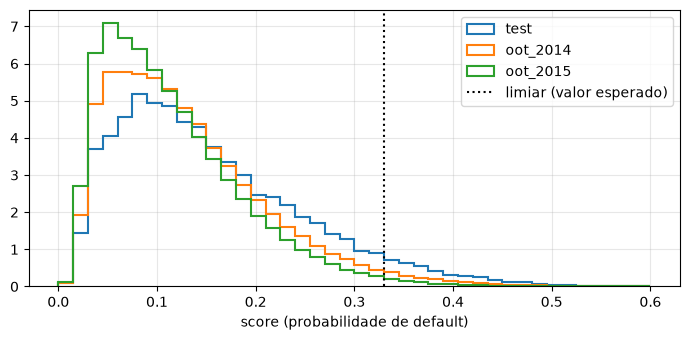

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.5))
bins = np.linspace(0, 0.6, 41)
for k in ("test", "oot_2014", "oot_2015"):
    ax.hist(scores[k], bins=bins, density=True, histtype="step", lw=1.5, label=k)
ax.axvline(profile["threshold"], color="k", ls=":", label="limiar (valor esperado)")
ax.set_xlabel("score (probabilidade de default)"); ax.legend(); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

O score de 2015 se desloca para a esquerda (PSI 0,23 no RUN): o modelo vê uma população *aparentemente* mais segura — em boa parte porque `int_rate`, a feature mais importante, caiu — enquanto o bad rate observado não caiu.

## 3. Trade-off do limiar (conjunto de calibração)

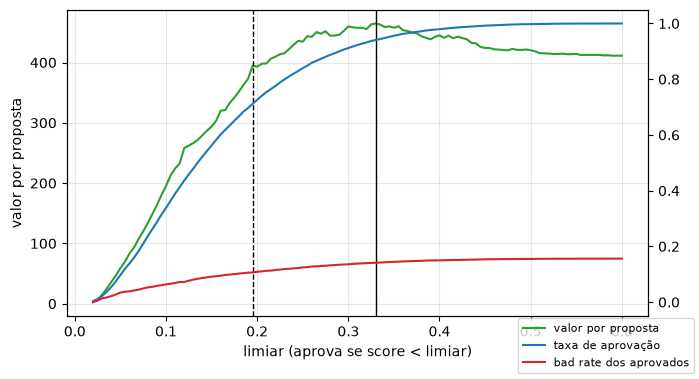

In [6]:
cal = sets["calibration"]; y = xy(cal)[1].to_numpy(); p = scores["calibration"]
gain, loss = loan_economics(cal, cost)
rows = [{"limiar": t, **decision_metrics(y, p, t), "valor_por_proposta": expected_value(y, p, gain, loss, t)}
        for t in threshold_grid(cost)]
curve = pd.DataFrame(rows)
fig, ax1 = plt.subplots(figsize=(7, 3.8)); ax2 = ax1.twinx()
ax1.plot(curve["limiar"], curve["valor_por_proposta"], color="tab:green", label="valor por proposta")
ax2.plot(curve["limiar"], curve["approval_rate"], color="tab:blue", label="taxa de aprovação")
ax2.plot(curve["limiar"], curve["bad_rate_approved"], color="tab:red", label="bad rate dos aprovados")
for t, s in ((profile["threshold"], "-"), (0.195, "--")):
    ax1.axvline(t, color="k", ls=s, lw=1)
ax1.set_xlabel("limiar (aprova se score < limiar)"); ax1.set_ylabel("valor por proposta")
fig.legend(loc="lower right", fontsize=8); ax1.grid(alpha=0.3); plt.tight_layout(); plt.show()

In [7]:
curve[curve["limiar"].isin([0.15, 0.195, 0.25, 0.30, 0.33, 0.40])].round(4)

,limiar,approval_rate,bad_rate_approved,valor_por_proposta
26,0.150,0.5623,0.0913,293.9152
35,0.195,0.7116,0.1062,394.5069
46,0.250,0.8396,0.1246,434.5580
56,0.300,0.9118,0.1358,459.8384
62,0.330,0.9406,0.1412,464.7460
76,0.400,0.9795,0.1498,445.0727


**Leitura.** Com as premissas PROPOSTAS de custo (LGD 60%, realização de margem 50%), o valor por proposta é
máximo perto de 0,33 e a curva é achatada: aprovar mais é barato porque a população já foi filtrada pela política do
credor (viés de seleção). O limiar do F1 (0,195) recusaria ~28% e perderia valor. A sensibilidade às premissas de custo
é discutida no ADR-0007.

## 4. Sensibilidade do limiar às premissas de custo

O ADR-0007 definiu como sinal de reversão: se LGD ∈ [0,4; 0,8] e realização de margem ∈ [0,3; 0,7] moverem o limiar
para fora de 0,25–0,40, as premissas precisam ser revistas. Grade avaliada no conjunto de calibração (função
`cost_sensitivity` de `src/models/threshold.py`).

In [8]:
from src.models.threshold import cost_sensitivity
sens = cost_sensitivity(cal, y, p, cost, lgds=[0.4, 0.5, 0.6, 0.7, 0.8], margins=[0.3, 0.4, 0.5, 0.6, 0.7])
sens.pivot(index="lgd", columns="margin_realization", values="threshold")

margin_realization,0.3,0.4,0.5,0.6,0.7
lgd,,,,,
0.4,0.265,0.420,0.420,0.495,0.550
0.5,0.120,0.330,0.420,0.420,0.495
0.6,0.120,0.195,0.330,0.420,0.420
0.7,0.070,0.120,0.245,0.330,0.420
0.8,0.060,0.120,0.195,0.265,0.330


In [9]:
sens.pivot(index="lgd", columns="margin_realization", values="approval_rate").round(3)

margin_realization,0.3,0.4,0.5,0.6,0.7
lgd,,,,,
0.4,0.866,0.986,0.986,0.997,1.000
0.5,0.436,0.941,0.986,0.986,0.997
0.6,0.436,0.712,0.941,0.986,0.986
0.7,0.184,0.436,0.829,0.941,0.986
0.8,0.139,0.436,0.712,0.866,0.941


In [10]:
inside = sens["threshold"].between(0.25, 0.40)
print(f"limiar dentro de 0,25–0,40 em {inside.sum()}/{len(sens)} combinações; "
      f"faixa observada {sens['threshold'].min():.3f}–{sens['threshold'].max():.3f}")

limiar dentro de 0,25–0,40 em 6/25 combinações; faixa observada 0.060–0.550


## 5. Importância das features (permutação, queda de AUC)

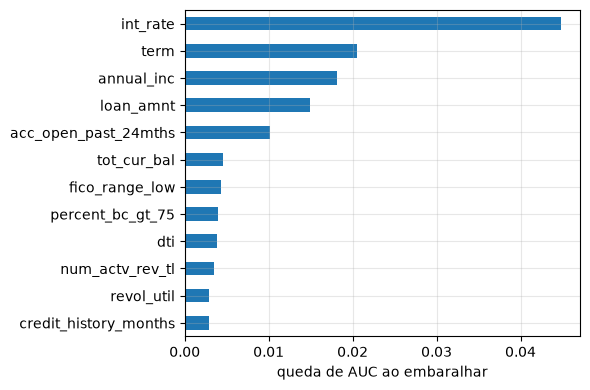

In [11]:
imp = pd.Series(profile["importance"]).head(12)[::-1]
fig, ax = plt.subplots(figsize=(6, 4)); imp.plot.barh(ax=ax); ax.set_xlabel("queda de AUC ao embaralhar")
ax.grid(alpha=0.3); plt.tight_layout(); plt.show()